# Yaw identification - neural-network model of the drone's rotation

**Advanced task: rotate the drone on itself.** Same job as `1_identification_linear.ipynb` and
`2_identification_nn.ipynb`, for the rotation instead of the altitude.

The 4 motors no longer receive the same command. `data_generation/generate_yaw_data.m` drove them
through a **mixer** (pairing found by its probe):

```
u1 = u3 = u_T + u_yaw          u_T   : collective thrust   (what the altitude policy controls)
u2 = u4 = u_T - u_yaw          u_yaw : differential command (turns the drone)
```

Structure of the problem, the same as for the altitude:

```
(u_yaw, u_T) --> [ unknown dynamics ] --> w_dot_z --(integrate)--> wz --(integrate)--> psi
                  ^                         ^
             this is what we identify    known calculus, free
```

We identify the **yaw acceleration** `w_dot_z`, not the angle `psi`: asking a network to output `psi`
would mean asking it to learn two integrators from data (conclusion 4 of notebook 2).

| section | question |
|---|---|
| 1-2 | load the data and **validate** it (outliers, pure yaw, kinematics) |
| 3 | **order** of the dynamics (step response), input delay |
| 4 | **static characteristic**: is it linear in `u_yaw`? does the gain depend on `u_T`? is there yaw drag? |
| 5 | **least-squares** models (linear, polynomial gain, physical tanh model) |
| 6 | the **neural network**, validated in free run |
| 7 | what matters for control: the **heading** predicted over the duration of a turn |
| 8 | **coupling**: does the rotation disturb the altitude? |
| 9 | save the model for the RL environment |

## 0. Setup

`N_ROWS` limits the number of experiments loaded (`None` = all). `N_TRAIN_MAX` caps the number of
samples given to the network: with 1000 experiments x 2000 samples there are 2 million, and a 3-input
smooth map does not need that many (notebook 2 converged on 0.8 million).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.io import loadmat
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

Ts          = 0.05
DATA        = os.path.join('..', 'data', 'yaw')
N_ROWS      = None          # experiments to load (None = all)
N_TRAIN_MAX = 1_000_000     # samples given to the network
N_REST      = 40            # samples at rest at the start of every experiment (u = 0)
SEED        = 0

plt.rcParams['figure.figsize'] = (11, 3.2); plt.rcParams['axes.grid'] = True
np.set_printoptions(suppress=True, precision=4)
os.makedirs('figures', exist_ok=True); os.makedirs('models', exist_ok=True)

## 1. Load the data

Same layout as the course's dataset: **one row per experiment, one column per sample** (Ts = 0.05 s).
The mixer pattern `S` and the noise level are read from `yaw_dataset.mat`, so the notebook always
matches the data it is given.

Signals used: the two commands `u_T`, `u_yaw`; the yaw acceleration `w_dot_z` (identified), the yaw
rate `wz` and angle `psi` (used to check the kinematics and the predicted heading), `az` (coupling
check, section 8), `phi` (tilt check). `theta` is **not** used: in `UAV_model.slx` its noise block has
a huge, seed-dependent variance, so it is unusable noise.

In [2]:
def load(name):
    return pd.read_csv(os.path.join(DATA, name), header=None, nrows=N_ROWS).to_numpy()

UT,  UY  = load('yaw_in_uT.csv'), load('yaw_in_uyaw.csv')
W,   WZ  = load('yaw_out_w_dot_z.csv'), load('yaw_out_wz.csv')
PSI, AZ  = load('yaw_out_psi.csv'), load('yaw_out_az.csv')
PHI      = load('yaw_out_phi.csv')
info     = loadmat(os.path.join(DATA, 'yaw_dataset.mat'), variable_names=['S', 'G_NOISE'])
S, G_NOISE = info['S'].ravel(), float(info['G_NOISE'])

n_exp, n_t = UT.shape
t = np.arange(n_t) * Ts
print(f'{n_exp} experiments x {n_t} samples ({n_t * Ts:.0f} s each), mixer S = {S}, g_noise = {G_NOISE}')
print(f'u_T in [{UT.min():.2f}, {UT.max():.2f}]   u_yaw in [{UY.min():.3f}, {UY.max():.3f}]')
print(f'w_dot_z in [{W.min():.1f}, {W.max():.1f}] rad/s^2   wz in [{WZ.min():.1f}, {WZ.max():.1f}] rad/s')

1000 experiments x 2000 samples (100 s each), mixer S = [ 1 -1  1 -1], g_noise = 0.01
u_T in [0.00, 0.80]   u_yaw in [-0.100, 0.100]
w_dot_z in [-19.9, 19.9] rad/s^2   wz in [-39.8, 46.7] rad/s


C:\Users\LOQ\AppData\Local\Temp\ipykernel_26272\136320488.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  S, G_NOISE = info['S'].ravel(), float(info['G_NOISE'])


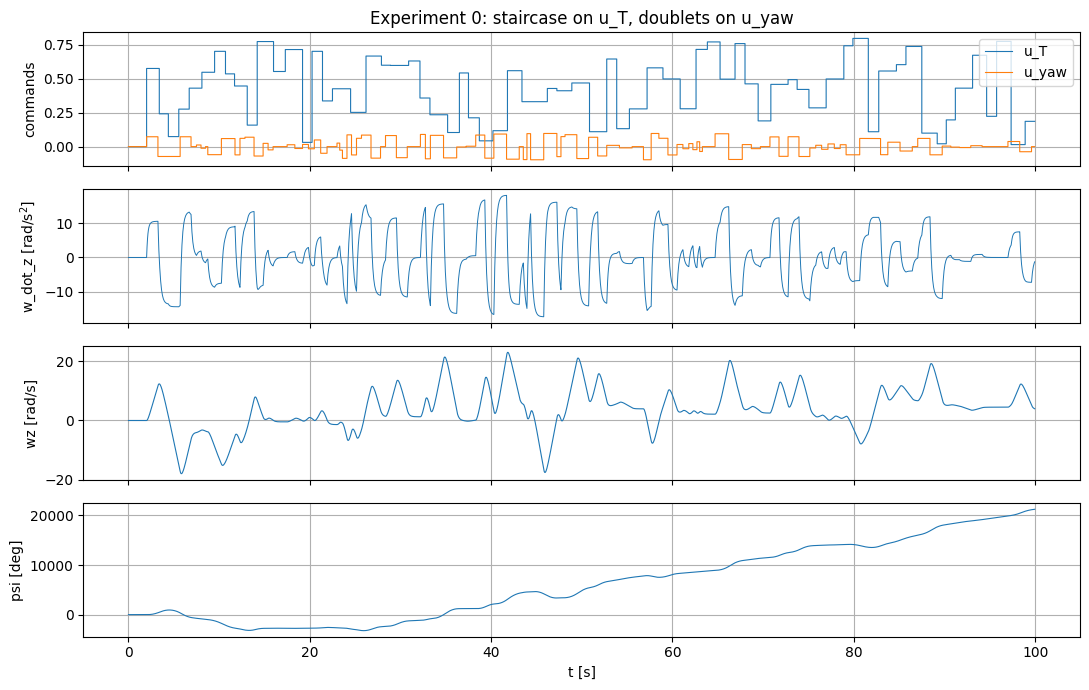

In [3]:
# what one experiment looks like
i = 0
fig, ax = plt.subplots(4, 1, sharex=True, figsize=(11, 7))
ax[0].step(t, UT[i], where='post', lw=.8, label='u_T'); ax[0].step(t, UY[i], where='post', lw=.8, label='u_yaw')
ax[0].legend(loc='upper right'); ax[0].set_ylabel('commands')
ax[1].plot(t, W[i], lw=.7);  ax[1].set_ylabel('w_dot_z [rad/s$^2$]')
ax[2].plot(t, WZ[i], lw=.8); ax[2].set_ylabel('wz [rad/s]')
ax[3].plot(t, np.degrees(PSI[i]), lw=.8); ax[3].set_ylabel('psi [deg]'); ax[3].set_xlabel('t [s]')
ax[0].set_title(f'Experiment {i}: staircase on u_T, doublets on u_yaw')
plt.tight_layout(); plt.show()

## 2. Validate the dataset

Same idea as notebook 1: physics-based checks, then drop whole experiments that fail.

* **rest check**: the first 40 samples are at `u = 0` (motors off): `w_dot_z` must be 0 (nothing turns
  the drone) and `az` must be $-g$;
* **amplitude check**: with $|u_{yaw}| \le 0.1$ the yaw acceleration stays around 20 rad/s²; anything
  far above is a sensor glitch;
* **pure yaw**: the roll `phi` must stay at 0. If it moved, the mixer would also tilt the drone and the
  rotation would not be decoupled from the horizontal motion.

In [4]:
rest_w  = np.abs(W[:, :N_REST]).max(axis=1)
rest_az = AZ[:, :N_REST].mean(axis=1)
peak_w  = np.abs(W).max(axis=1)
finite  = np.isfinite(W).all(1) & np.isfinite(UY).all(1) & np.isfinite(AZ).all(1)

bad = ~finite | (rest_w > 0.5) | (np.abs(rest_az + 9.81) > 0.5) | (peak_w > 60)
print(f'rest |w_dot_z| max : {rest_w.max():.4f} rad/s^2      rest az: {rest_az.min():.3f} .. {rest_az.max():.3f}')
print(f'peak |w_dot_z|     : median {np.median(peak_w):.1f}   max {peak_w.max():.1f} rad/s^2')
print(f'max |phi| (tilt)   : {np.abs(PHI).max():.4f} rad   -> {"pure yaw" if np.abs(PHI).max() < 0.02 else "THE DRONE TILTS: check the mixer"}')
print(f'\nCORRUPTED EXPERIMENTS: {bad.sum()} / {n_exp}  -> rows {np.flatnonzero(bad)[:20]}')

keep = ~bad
UT, UY, W, WZ, PSI, AZ, PHI = (A[keep] for A in (UT, UY, W, WZ, PSI, AZ, PHI))
n_exp = len(UT)
print(f'{n_exp} experiments kept')

rest |w_dot_z| max : 0.0022 rad/s^2      rest az: -9.810 .. -9.810
peak |w_dot_z|     : median 18.4   max 19.9 rad/s^2
max |phi| (tilt)   : 0.0022 rad   -> pure yaw

CORRUPTED EXPERIMENTS: 0 / 1000  -> rows []
1000 experiments kept


### Kinematics: are `wz` and `psi` really the integrals of `w_dot_z`?

The whole approach (identify `w_dot_z`, integrate the rest) relies on it. We compare the measured
increments with two integration rules: **forward Euler** ($w_z[k+1] = w_z[k] + T_s\,\dot w_z[k]$) and
the **trapezoid** ($T_s(\dot w_z[k] + \dot w_z[k+1])/2$, exact if $\dot w_z$ is linear between samples,
the rule used by `drone_env.py` for the altitude). The smaller residual tells which one to use in the
RL environment.

In [5]:
d_wz = np.diff(WZ, axis=1)
res_euler = d_wz - Ts * W[:, :-1]
res_trap  = d_wz - Ts * (W[:, :-1] + W[:, 1:]) / 2
d_psi = np.diff(PSI, axis=1)
res_psi = d_psi - Ts * (WZ[:, :-1] + WZ[:, 1:]) / 2
print(f'wz  increment vs Euler    : rms residual {res_euler.std():.5f} rad/s')
print(f'wz  increment vs trapezoid: rms residual {res_trap.std():.5f} rad/s')
print(f'psi increment vs trapezoid: rms residual {res_psi.std():.5f} rad  ({np.degrees(res_psi.std()):.3f} deg)')
print(f'(typical wz increment: {np.abs(d_wz).mean():.4f} rad/s per sample)')

wz  increment vs Euler    : rms residual 0.03220 rad/s
wz  increment vs trapezoid: rms residual 0.00128 rad/s
psi increment vs trapezoid: rms residual 0.00067 rad  (0.038 deg)
(typical wz increment: 0.2702 rad/s per sample)


### Helper: constant-command holds, and the measurement noise

A **hold** is a stretch where *both* commands are constant. Inside a long enough hold the motors
have settled, so `w_dot_z` is at steady state: this is what sections 3 and 4 use. The scatter of
`w_dot_z` inside settled holds (successive differences, which remove any slow drift) measures the
sensor noise: **no model can do better than this floor**.

In [6]:
def holds(i, min_len=1):
    """[start, stop) index pairs over which u_T AND u_yaw are both constant, in experiment i."""
    change = (np.diff(UT[i]) != 0) | (np.diff(UY[i]) != 0)
    edges = np.concatenate(([0], np.flatnonzero(change) + 1, [n_t]))
    return [(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a >= min_len]

res = []
for i in range(min(200, n_exp)):
    for a, b in holds(i, 20):
        seg = W[i, a + 10:b]                                  # skip 10 samples = 2.5 tau of transient
        if len(seg) > 5:
            res.append(np.diff(seg) / np.sqrt(2))
res = np.concatenate(res)
noise_std = res.std()
L = [b - a for a, b in holds(0)]
print(f'experiment 0: {len(L)} holds, median length {int(np.median(L))} samples ({np.median(L) * Ts:.2f} s)')
print(f'measurement noise on w_dot_z inside settled holds: std = {noise_std:.4f} rad/s^2')

experiment 0: 167 holds, median length 11 samples (0.55 s)
measurement noise on w_dot_z inside settled holds: std = 0.0698 rad/s^2


## 3. Order of the dynamics

Same criterion as notebook 1: no overshoot and a **nonzero** initial slope means **first order**.
We collect the response of `w_dot_z` to isolated jumps of `u_yaw` (with `u_T` constant over the whole
window, so only the yaw command moves), normalise each from 0 to 1 and average them.

Sample 0 is the one at which `u_yaw` jumps. If `w_dot_z` only starts moving at sample 1, there is
**one sample of input delay**, exactly as for the altitude: `w_dot_z[k+1]` depends on `u_yaw[k]`.

156 isolated steps collected
normalised response at samples 0, 1, 2: [0.    0.223 0.396]   (0 at sample 0 = one sample of delay)
time constant from the 63.2 % crossing: tau = 0.198 s   (altitude: 0.196 s)


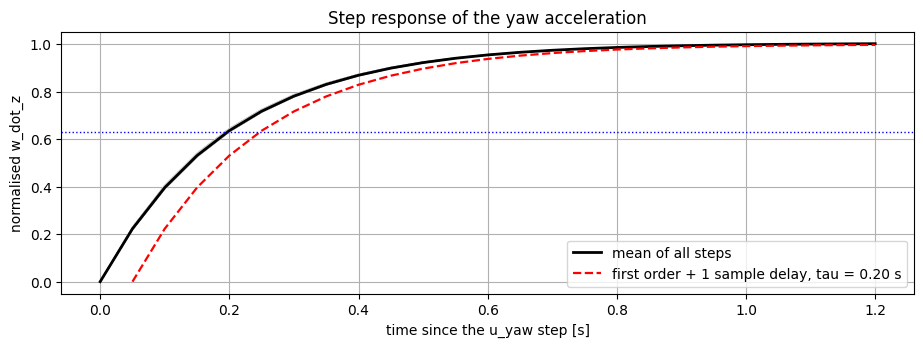

In [7]:
def step_responses(n_use=300, min_jump=0.04, pre=10, post=25):
    out = []
    for i in range(min(n_use, n_exp)):
        jumps = np.flatnonzero(np.diff(UY[i]) != 0) + 1
        for a in jumps:
            if a - pre < N_REST or a + post > n_t:
                continue
            win_T, before, after = UT[i, a - pre:a + post], UY[i, a - pre:a], UY[i, a:a + post]
            if np.ptp(win_T) == 0 and np.ptp(before) == 0 and np.ptp(after) == 0 \
                    and abs(after[0] - before[0]) > min_jump:
                y0, y1 = W[i, a], W[i, a + post - 5:a + post].mean()
                if abs(y1 - y0) > 1.0:
                    out.append((W[i, a:a + post] - y0) / (y1 - y0))
    return np.array(out)

R = step_responses()
mean = R.mean(axis=0)
tt = np.arange(len(mean)) * Ts
k63 = np.argmax(mean > 0.632)
tau_yaw = np.interp(0.632, mean[:k63 + 1], tt[:k63 + 1])
print(f'{len(R)} isolated steps collected')
print(f'normalised response at samples 0, 1, 2: {mean[:3].round(3)}   (0 at sample 0 = one sample of delay)')
print(f'time constant from the 63.2 % crossing: tau = {tau_yaw:.3f} s   (altitude: 0.196 s)')

plt.figure(figsize=(11, 3.4))
plt.plot(tt, R[:150].T, color='0.8', lw=.6)
plt.plot(tt, mean, 'k', lw=2, label='mean of all steps')
plt.plot(tt[1:], 1 - np.exp(-(tt[1:] - Ts) / tau_yaw), 'r--', lw=1.6, label=f'first order + 1 sample delay, tau = {tau_yaw:.2f} s')
plt.axhline(0.632, color='b', ls=':', lw=1)
plt.xlabel('time since the u_yaw step [s]'); plt.ylabel('normalised w_dot_z'); plt.legend()
plt.title('Step response of the yaw acceleration'); plt.show()

## 4. Static characteristic: linear? dependent on the thrust? drag?

At the end of every long hold, `w_dot_z` is at steady state. We read it against `u_yaw`, colouring by
`u_T`. Three questions:

1. **Linear in `u_yaw`?** At fixed `u_T`, are the points on a straight line through the origin?
2. **Does the gain depend on `u_T`?** Each motor saturates (the `tanh` of notebook 1), so the same
   `u_yaw` should give *less* torque when the motors are already running fast. Expected: the gain
   falls as `u_T` rises.
3. **Yaw drag?** In the pauses (`u_yaw = 0`), does `w_dot_z` go back to 0 whatever the rotation
   speed, or is it pulled towards $-k\,w_z$ (aerodynamic drag)? No drag means that once turning, the
   drone keeps turning until the controller actively brakes it.

27382 settled points

 u_T range    n    gain d(w_dot_z)/d(u_yaw)   linear-fit residual
  0.0..0.2   5205        195.2 rad/s^2 per unit     0.159 rad/s^2
  0.2..0.4   5173        180.5 rad/s^2 per unit     0.363 rad/s^2
  0.4..0.6   5152        155.6 rad/s^2 per unit     0.490 rad/s^2
  0.6..0.8   5084        126.2 rad/s^2 per unit     0.512 rad/s^2

pauses (u_yaw = 0): w_dot_z = +0.00006 * wz + ...  over wz in [-24.7, 26.4] rad/s
  -> no measurable yaw drag


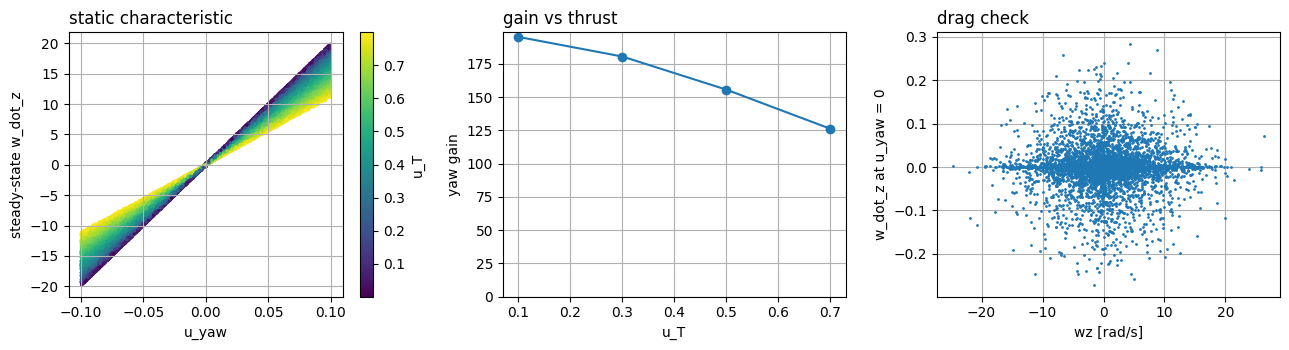

In [8]:
u_T_ss, u_y_ss, w_ss, wz_ss = [], [], [], []
for i in range(n_exp):
    for a, b in holds(i, 20):                       # >= 1 s = 5 tau: settled
        if a >= N_REST:
            u_T_ss.append(UT[i, a]); u_y_ss.append(UY[i, a])
            w_ss.append(np.median(W[i, b - 5:b])); wz_ss.append(WZ[i, b - 1])
u_T_ss, u_y_ss, w_ss, wz_ss = map(np.array, (u_T_ss, u_y_ss, w_ss, wz_ss))
print(f'{len(w_ss)} settled points')

bins = np.arange(0, 0.81, 0.2)
print('\n u_T range    n    gain d(w_dot_z)/d(u_yaw)   linear-fit residual')
gains = []
for lo in bins[:-1]:
    m = (u_T_ss >= lo) & (u_T_ss < lo + 0.2) & (u_y_ss != 0)
    if m.sum() > 10:
        k = np.sum(u_y_ss[m] * w_ss[m]) / np.sum(u_y_ss[m] ** 2)      # slope through the origin
        r = (w_ss[m] - k * u_y_ss[m]).std()
        gains.append((lo + 0.1, k))
        print(f'  {lo:.1f}..{lo + 0.2:.1f}  {m.sum():5d}   {k:10.1f} rad/s^2 per unit     {r:.3f} rad/s^2')
gains = np.array(gains)

m0 = u_y_ss == 0
if m0.sum() > 5:
    k_drag = np.polyfit(wz_ss[m0], w_ss[m0], 1)[0]
    print(f'\npauses (u_yaw = 0): w_dot_z = {k_drag:+.5f} * wz + ...  over wz in [{wz_ss[m0].min():.1f}, {wz_ss[m0].max():.1f}] rad/s'
          f'\n  -> {"no measurable yaw drag" if abs(k_drag) < 0.01 else "YAW DRAG present: keep wz as a model input"}')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
sc = ax[0].scatter(u_y_ss, w_ss, c=u_T_ss, s=2, cmap='viridis'); plt.colorbar(sc, ax=ax[0], label='u_T')
ax[0].set_xlabel('u_yaw'); ax[0].set_ylabel('steady-state w_dot_z'); ax[0].set_title('static characteristic', loc='left')
if len(gains):
    ax[1].plot(gains[:, 0], gains[:, 1], 'o-'); ax[1].set_ylim(0, None)
ax[1].set_xlabel('u_T'); ax[1].set_ylabel('yaw gain'); ax[1].set_title('gain vs thrust', loc='left')
if m0.sum() > 5:
    ax[2].plot(wz_ss[m0], w_ss[m0], '.', ms=2)
ax[2].set_xlabel('wz [rad/s]'); ax[2].set_ylabel('w_dot_z at u_yaw = 0'); ax[2].set_title('drag check', loc='left')
plt.tight_layout(); plt.show()

## 5. Identification by least squares

Discrete first-order model with one sample of delay, as for the altitude:

$$\dot w_z[k+1] \;=\; a\,\dot w_z[k] \;+\; \sum_j b_j\,g_j\big(u_T[k],\,u_{yaw}[k]\big) \;+\; c$$

For any fixed choice of the functions $g_j$ the model is **linear in the parameters**, so least
squares applies. Three candidates:

| model | $g_j$ | idea |
|---|---|---|
| **A** linear | $u_{yaw}$ | constant gain: ignores the thrust |
| **B** polynomial gain | $u_{yaw},\ u_{yaw}u_T,\ u_{yaw}u_T^2$ | the gain is a smooth function of $u_T$ |
| **C** physical | $\tanh(\beta(u_T+u_{yaw})) - \tanh(\beta(u_T-u_{yaw}))$ | each pair of motors is the saturating actuator of notebook 1; the torque is the *difference* between the two pairs |

Model C has a single shape parameter $\beta$, fitted by separable least squares (scan $\beta$, solve
the linear problem at each value), on the training experiments only. If C fits as well as B with
fewer parameters, and its $\beta$ is close to the 0.9 of the altitude model, the physical picture
(4 identical saturating motors) is confirmed by two independent datasets.

Two free checks on every model: the pole $a$ gives back the time constant of section 3,
$\tau = -T_s/\ln a$; and $c \approx 0$ (no torque when the commands are symmetric).

750 experiments for identification, 250 held out for validation
best beta = 1.00   (altitude model of notebook 1: 0.90)


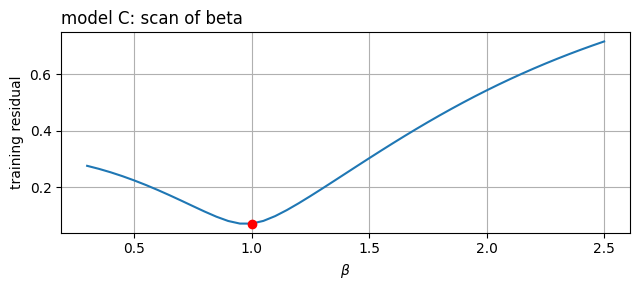

In [9]:
rng = np.random.default_rng(SEED)
split = int(0.75 * n_exp)
train, test = np.arange(split), np.arange(split, n_exp)
print(f'{len(train)} experiments for identification, {len(test)} held out for validation')

def design(rows, basis):
    X, y = [], []
    for i in rows:
        uT, uy, w0, w1 = UT[i, :-1], UY[i, :-1], W[i, :-1], W[i, 1:]
        X.append(np.column_stack([w0] + [g(uT, uy) for g in basis] + [np.ones_like(uy)]))
        y.append(w1)
    return np.vstack(X), np.concatenate(y)

def identify(basis, rows=None):
    X, y = design(train if rows is None else rows, basis)
    return np.linalg.lstsq(X, y, rcond=None)[0]

def tanh_basis(beta):
    return [lambda uT, uy, b=beta: np.tanh(b * (uT + uy)) - np.tanh(b * (uT - uy))]

# separable least squares for beta (model C), on a subset of the training experiments
scan_rows = train[:min(len(train), 200)]
betas = np.arange(0.3, 2.51, 0.05)
err_b = []
for bt in betas:
    X, y = design(scan_rows, tanh_basis(bt))
    err_b.append((y - X @ identify(tanh_basis(bt), scan_rows)).std())
beta_opt = betas[int(np.argmin(err_b))]
print(f'best beta = {beta_opt:.2f}   (altitude model of notebook 1: 0.90)')

plt.figure(figsize=(6.5, 3)); plt.plot(betas, err_b); plt.plot(beta_opt, min(err_b), 'ro')
plt.xlabel(r'$\beta$'); plt.ylabel('training residual'); plt.title('model C: scan of beta', loc='left')
plt.tight_layout(); plt.show()

In [10]:
BASES = {
    'A  linear        ': [lambda uT, uy: uy],
    'B  poly gain     ': [lambda uT, uy: uy, lambda uT, uy: uy * uT, lambda uT, uy: uy * uT ** 2],
    'C  tanh (physics)': tanh_basis(beta_opt),
}
theta = {name: identify(b) for name, b in BASES.items()}
for name, th in theta.items():
    a = th[0]
    print(f'{name}  theta = {np.round(th, 4)}')
    print(f'{"":19s} tau = {-Ts / np.log(a):.3f} s  (step response: {tau_yaw:.3f} s)   c = {th[-1]:+.4f} (expect ~0)')

A  linear          theta = [ 0.79   35.6471  0.0009]
                    tau = 0.212 s  (step response: 0.198 s)   c = +0.0009 (expect ~0)
B  poly gain       theta = [  0.779   44.8382 -10.0877 -18.6297  -0.0001]
                    tau = 0.200 s  (step response: 0.198 s)   c = -0.0001 (expect ~0)
C  tanh (physics)  theta = [ 0.7791 22.182  -0.0001]
                    tau = 0.200 s  (step response: 0.198 s)   c = -0.0001 (expect ~0)


## 6. The neural network

Same recipe as notebook 2, one more input:

$$\dot w_z[k+1] = F\big(\dot w_z[k],\ u_{yaw}[k],\ u_T[k]\big)$$

| choice | value | why |
|---|---|---|
| inputs | $\dot w_z[k], u_{yaw}[k], u_T[k]$ | first order (section 3) so one lag is enough; $u_T$ because the gain depends on it (section 4) |
| scaling | standardised inputs and output | $u_{yaw}$ spans 0.2, $\dot w_z$ spans 40: without scaling the optimiser does not see $u_{yaw}$ |
| network | one hidden layer, 16 tanh units | smooth saturating map; tanh keeps the learned gains smooth for the controller |
| training | Adam, batch 256, early stopping on 15 % | stop before fitting the sensor noise |

If section 4 found **yaw drag**, add `wz[k]` as a 4th input (one line in `dataset()`).

The honest test is the **free run**: the model gets only the two commands and feeds back its own
output for the whole 100 s, so errors compound.

In [11]:
def dataset(rows):
    X = np.concatenate([np.column_stack([W[i, :-1], UY[i, :-1], UT[i, :-1]]) for i in rows])
    y = np.concatenate([W[i, 1:] for i in rows])
    return X, y

X_tr, y_tr = dataset(train)
if len(y_tr) > N_TRAIN_MAX:                                   # random subsample of the samples
    idx = rng.choice(len(y_tr), N_TRAIN_MAX, replace=False)
    X_tr, y_tr = X_tr[idx], y_tr[idx]
X_te, y_te = dataset(test)

sx = StandardScaler().fit(X_tr)
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
net = MLPRegressor(hidden_layer_sizes=(16,), activation='tanh', solver='adam', learning_rate_init=1e-3,
                   batch_size=256, max_iter=60, early_stopping=True, n_iter_no_change=5,
                   validation_fraction=0.15, random_state=SEED)
net.fit(sx.transform(X_tr), sy.transform(y_tr.reshape(-1, 1)).ravel())
print(f'{len(y_tr):,} training samples; stopped after {net.n_iter_} epochs, '
      f'{sum(c.size for c in net.coefs_) + sum(b.size for b in net.intercepts_)} parameters')

def predict(X):
    return sy.inverse_transform(net.predict(sx.transform(X)).reshape(-1, 1)).ravel()

1,000,000 training samples; stopped after 8 epochs, 81 parameters


In [12]:
def free_run_nn(rows):
    w = np.zeros((len(rows), n_t)); w[:, 0] = W[rows, 0]
    for k in range(n_t - 1):
        w[:, k + 1] = predict(np.column_stack([w[:, k], UY[rows, k], UT[rows, k]]))
    return w

def free_run_ls(th, basis, rows):
    a, b, c = th[0], th[1:-1], th[-1]
    w = np.zeros((len(rows), n_t)); w[:, 0] = W[rows, 0]
    for k in range(n_t - 1):
        uT, uy = UT[rows, k], UY[rows, k]
        w[:, k + 1] = a * w[:, k] + sum(bj * g(uT, uy) for bj, g in zip(b, basis)) + c
    return w

sub = test[:100]
rmse = lambda p, rows: float(np.sqrt(np.mean((p - W[rows]) ** 2)))
print(f'{"model":19s} {"params":>7s} {"one-step":>10s} {"free-run":>10s}   [rad/s^2]')
free = {}
for name, basis in BASES.items():
    X, y = design(test, basis)
    free[name] = free_run_ls(theta[name], basis, sub)
    print(f'{name:19s} {len(theta[name]):7d} {(y - X @ theta[name]).std():10.4f} {rmse(free[name], sub):10.4f}')
free['NN'] = free_run_nn(sub)
print(f'{"neural network":19s} {sum(c.size for c in net.coefs_) + sum(b.size for b in net.intercepts_):7d} '
      f'{np.sqrt(np.mean((predict(X_te) - y_te) ** 2)):10.4f} {rmse(free["NN"], sub):10.4f}')
print(f'{"measurement noise":19s} {"":7s} {noise_std:10.4f}')

model                params   one-step   free-run   [rad/s^2]
A  linear                 3     0.3072     1.1324
B  poly gain              5     0.0733     0.1853
C  tanh (physics)         3     0.0736     0.1866
neural network           81     0.0721     0.1882
measurement noise               0.0698


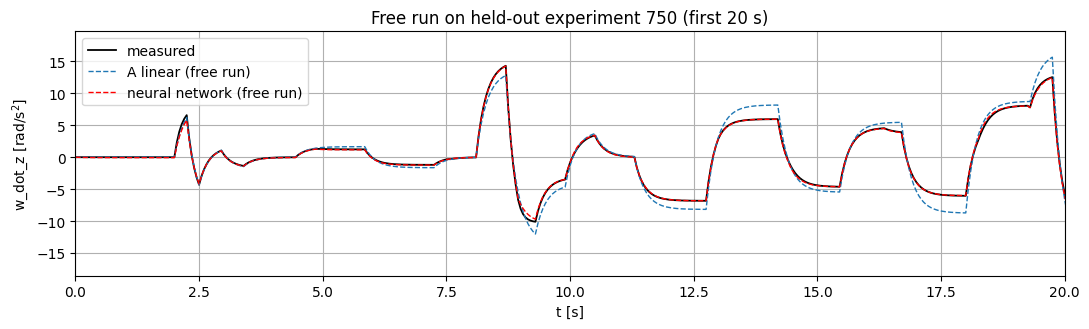

In [13]:
i = 0
plt.figure(figsize=(11, 3.4))
plt.plot(t, W[sub[i]], 'k', lw=1.3, label='measured')
plt.plot(t, free['A  linear        '][i], '--', lw=1, label='A linear (free run)')
plt.plot(t, free['NN'][i], 'r--', lw=1, label='neural network (free run)')
plt.xlim(0, 20); plt.xlabel('t [s]'); plt.ylabel('w_dot_z [rad/s$^2$]'); plt.legend()
plt.title(f'Free run on held-out experiment {sub[i]} (first 20 s)'); plt.tight_layout(); plt.show()

### What did the network learn?

The static characteristic is the fixed point of the learned map, $\dot w_z = F(\dot w_z, u_{yaw}, u_T)$
for constant commands. If the network is sound, it must reproduce the measured steady states of
section 4, including the drop of gain with the thrust, without having been told about it.

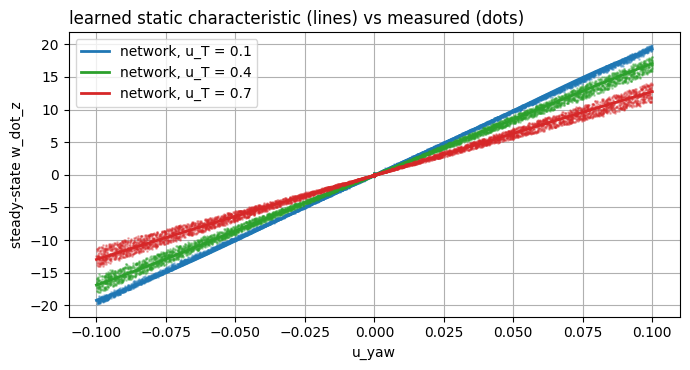

In [14]:
uy_grid = np.linspace(UY.min(), UY.max(), 81)
plt.figure(figsize=(7, 3.8))
for uT0, c in zip((0.1, 0.4, 0.7), ('tab:blue', 'tab:green', 'tab:red')):
    w = np.zeros_like(uy_grid)
    for _ in range(200):
        w = predict(np.column_stack([w, uy_grid, np.full_like(uy_grid, uT0)]))
    m = np.abs(u_T_ss - uT0) < 0.1
    plt.plot(u_y_ss[m], w_ss[m], '.', ms=2, color=c, alpha=.3)
    plt.plot(uy_grid, w, color=c, lw=2, label=f'network, u_T = {uT0}')
plt.xlabel('u_yaw'); plt.ylabel('steady-state w_dot_z'); plt.legend()
plt.title('learned static characteristic (lines) vs measured (dots)', loc='left'); plt.tight_layout(); plt.show()

## 7. What matters for control: the heading over the duration of a turn

The controller will act on `psi`, the **double** integral of `w_dot_z`. Over 100 s any model error
accumulates without bound (no drag: nothing pulls `wz` back), so a 100 s free run of `psi` says little.
What matters is the horizon of one manoeuvre: a 90° turn takes 1 to 3 s, and the controller corrects
the heading at every step.

So we start the model from the **measured** state at many random instants, simulate **3 s** (60
samples) with the true commands, and compare the predicted heading with the measured one. This is the
error the RL policy will have to absorb when it moves from the model to the simulator.

In [15]:
H = 60                                      # 3 s horizon
starts = [(i, k) for i in sub for k in rng.integers(N_REST, n_t - H, 20)]
def heading_error(step_fn):
    errs = []
    for i, k in starts:
        w, wz, psi = W[i, k], WZ[i, k], PSI[i, k]
        for j in range(H):
            w1 = step_fn(w, UY[i, k + j], UT[i, k + j])
            wz1 = wz + Ts * (w + w1) / 2
            psi += Ts * (wz + wz1) / 2
            w, wz = w1, wz1
        errs.append(psi - PSI[i, k + H])
    return np.degrees(np.abs(np.array(errs)))

nn_step = lambda w, uy, uT: float(predict(np.array([[w, uy, uT]]))[0])
thA, thC = theta['A  linear        '], theta['C  tanh (physics)']
A_step = lambda w, uy, uT: thA[0] * w + thA[1] * uy + thA[2]
C_step = lambda w, uy, uT: thC[0] * w + thC[1] * (np.tanh(beta_opt * (uT + uy)) - np.tanh(beta_opt * (uT - uy))) + thC[2]
print(f'heading error after {H * Ts:.0f} s, over {len(starts)} random starts   (median / 90th percentile)')
for name, f in (('A linear', A_step), ('C tanh', C_step), ('neural network', nn_step)):
    e = heading_error(f)
    print(f'  {name:15s}: {np.median(e):6.2f} deg / {np.percentile(e, 90):6.2f} deg')

heading error after 3 s, over 2000 random starts   (median / 90th percentile)
  A linear       :  65.03 deg / 239.66 deg
  C tanh         :   6.18 deg /  32.11 deg
  neural network :  11.74 deg /  34.88 deg


## 8. Coupling: does the rotation disturb the altitude?

Option A of the plan keeps the **altitude policy unchanged** and adds a yaw policy next to it. That is
only sound if `u_yaw` barely changes the vertical thrust. Physically, speeding one pair up and slowing
the other down by the same amount loses a little thrust because each motor saturates (roughly in
proportion to $u_{yaw}^2$).

We run the **altitude NN of notebook 2** (`models/drone_model_nn.joblib`, which knows only `u_T`) in
free run on these experiments, and look at what it misses: if the residual on `az` grows with
$u_{yaw}^2$, that is the coupling, and its size tells whether the altitude policy (which tolerates
thrust offsets of ±0.4 m/s² by design) can absorb it.

az residual of the altitude model (u_T only): rms 0.041 m/s^2
fit  az_residual = -4.5 * u_yaw^2   ->  at u_yaw = 0.05: -0.0113 m/s^2, at u_yaw = 0.1: -0.0452 m/s^2
(the altitude policy was trained with hover offsets up to +/- 0.4 m/s^2)


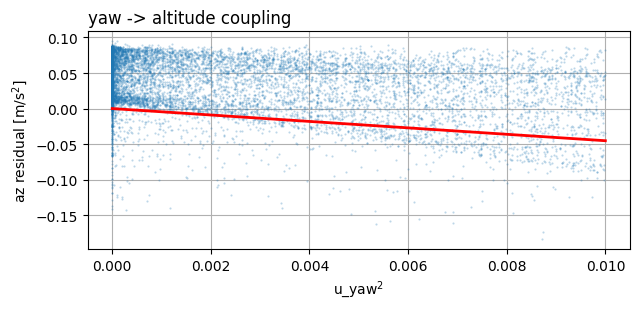

In [16]:
alt = joblib.load(os.path.join('models', 'drone_model_nn.joblib'))
def az_free_run(rows):
    az = np.zeros((len(rows), n_t)); az[:, 0] = AZ[rows, 0]
    for k in range(n_t - 1):
        x = alt['sx'].transform(np.column_stack([az[:, k], UT[rows, k]]))
        az[:, k + 1] = alt['sy'].inverse_transform(alt['net'].predict(x).reshape(-1, 1)).ravel()
    return az

az_hat = az_free_run(sub)
r_az = (AZ[sub] - az_hat)[:, N_REST:].ravel()
uy2 = (UY[sub][:, N_REST:] ** 2).ravel()
slope = np.polyfit(uy2, r_az, 1)[0]
print(f'az residual of the altitude model (u_T only): rms {r_az.std():.3f} m/s^2')
print(f'fit  az_residual = {slope:.1f} * u_yaw^2   ->  at u_yaw = 0.05: {slope * 0.05 ** 2:+.4f} m/s^2, '
      f'at u_yaw = 0.1: {slope * 0.1 ** 2:+.4f} m/s^2')
print('(the altitude policy was trained with hover offsets up to +/- 0.4 m/s^2)')

plt.figure(figsize=(6.5, 3.2))
plt.plot(uy2[::20], r_az[::20], '.', ms=1, alpha=.3)
g = np.linspace(0, uy2.max(), 50); plt.plot(g, slope * g, 'r', lw=2)
plt.xlabel('u_yaw$^2$'); plt.ylabel('az residual [m/s$^2$]'); plt.title('yaw -> altitude coupling', loc='left')
plt.tight_layout(); plt.show()

## 9. Save the model for the RL environment

Same contract as `models/drone_model_nn.joblib`, so the yaw environment can wrap it the same way as
`NNPlant` does for the altitude. Saved with it: the mixer `S`, the time constant, and the coefficients
of the physical model C (useful for a PID baseline with feedback linearisation, like the altitude one).

In [17]:
joblib.dump({'net': net, 'sx': sx, 'sy': sy, 'Ts': Ts,
             'inputs': ('w_dot_z[k]', 'u_yaw[k]', 'u_T[k]'), 'output': 'w_dot_z[k+1]',
             'S': S, 'tau': float(tau_yaw), 'yaw_max_data': float(np.abs(UY).max()),
             'theta_C': theta['C  tanh (physics)'], 'beta_C': float(beta_opt)},
            os.path.join('models', 'yaw_model_nn.joblib'))
print('saved models/yaw_model_nn.joblib')
print('check: commands at rest (u_yaw = 0) ->', round(float(predict(np.array([[0.0, 0.0, 0.39]]))[0]), 4), 'rad/s^2 (expect ~0)')

saved models/yaw_model_nn.joblib
check: commands at rest (u_yaw = 0) -> -0.0062 rad/s^2 (expect ~0)


## 10. Conclusions (to write once the notebook has run on the full dataset)

Read the numbers printed above and answer, in this order:

1. **Dataset**: how many experiments were dropped, and why? Is `phi` at 0 (pure yaw)? Which
   integration rule matches the simulator's kinematics (section 2)?
2. **Order and delay**: first order? same time constant as the altitude (0.2 s, same motors)? one
   sample of delay (section 3)?
3. **Linearity**: is `w_dot_z` linear in `u_yaw` at fixed thrust, and by how much does the gain drop
   between `u_T = 0.1` and `0.7`? Is there yaw drag (section 4)?
4. **Models**: does the physical model C match the polynomial model B with fewer parameters, and is
   its $\beta$ close to the 0.9 of the altitude? How close is the network to the noise floor in free
   run (sections 5-6)?
5. **For the controller**: the heading error over 3 s (section 7) is the model-to-simulator gap the
   policy must absorb; the coupling of section 8 says whether keeping the altitude policy unchanged
   (option A) is justified.